# 1 – Sayısal İntegrasyon: Günde kaç kWh enerji üretildi?

**Veri:** Kaggle – *Solar Power Generation Data* (Ani Kannal), Plant 1. 22 inverter, 15 Mayıs – 17 Haziran 2020, 15 dakikada bir ölçüm.

İnverterler 15 dakikada bir anlık güç (`AC_POWER`, kW) veriyor. Günlük enerji bu gücün zamana göre integralidir:
$$E = \int P(t)\,dt \quad [\text{kW} \times \text{saat} = \text{kWh}]$$
İntegrali trapez, Simpson ve Romberg ile hesaplayıp inverterin kendi enerji sayacıyla (`TOTAL_YIELD`) karşılaştıracağız.

Kütüphaneleri yüklüyoruz. CSV dosyaları defterle aynı klasörde ya da `../data` klasöründe olabilir.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate

VERI = Path(".") if Path("Plant_1_Generation_Data.csv").exists() else Path("../data")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Veri

Gece güç 0, üretim 06:00–18:30 arasında. Bu yüzden integrali **04:00–20:00** arasında alıyoruz: 16 saat = 64 aralık = 65 nokta.
64 = 2⁶ olduğu için bu ızgara Romberg'e de uygun. Sadece 65 noktanın hepsi mevcut olan inverter-günleri kullanıyoruz.
Referans enerji: $E_{\text{ref}} = \text{TOTAL\_YIELD}(20{:}00) - \text{TOTAL\_YIELD}(04{:}00)$.

In [2]:
df = pd.read_csv(VERI / "Plant_1_Generation_Data.csv")
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], format="%d-%m-%Y %H:%M")
df["tarih"] = df["DATE_TIME"].dt.date
df["saat"] = df["DATE_TIME"].dt.hour + df["DATE_TIME"].dt.minute / 60
df = df.sort_values(["SOURCE_KEY", "DATE_TIME"])

pencere = df[(df["saat"] >= 4) & (df["saat"] <= 20)]
gunler, ref = {}, {}          # (inverter, tarih) -> güç dizisi ve referans enerji
for anahtar, g in pencere.groupby(["SOURCE_KEY", "tarih"]):
    if len(g) == 65:
        gunler[anahtar] = g["AC_POWER"].to_numpy()
        ref[anahtar] = g["TOTAL_YIELD"].iloc[-1] - g["TOTAL_YIELD"].iloc[0]

h = 0.25                      # adım boyu: 15 dk = 0,25 saat
t = np.linspace(4, 20, 65)
print("İnverter sayısı           :", df["SOURCE_KEY"].nunique())
print("Tam (65 nokta) inverter-gün:", len(gunler), "/", pencere.groupby(["SOURCE_KEY", "tarih"]).ngroups)

İnverter sayısı           : 22
Tam (65 nokta) inverter-gün: 487 / 748


Tek bir inverterin tek bir gününe bakalım. Eğri öğleden sonra bulutlar yüzünden zıplıyor; bunun sonuçlarda önemli olduğunu göreceğiz.

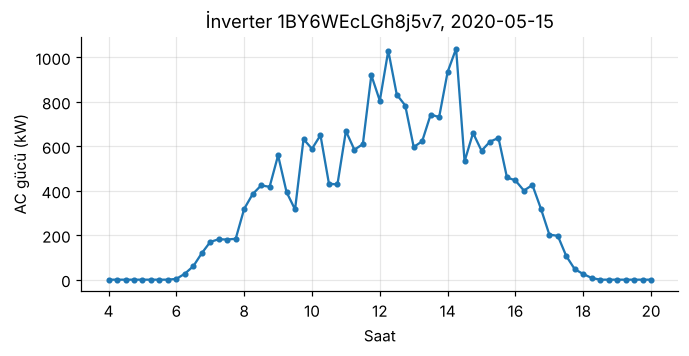

In [3]:
ornek = list(gunler)[0]
plt.figure(figsize=(7, 3))
plt.plot(t, gunler[ornek], "o-", ms=3)
plt.xlabel("Saat"); plt.ylabel("AC gücü (kW)")
plt.title(f"İnverter {ornek[0]}, {ornek[1]}")
plt.xticks(range(4, 21, 2))
plt.show()

## 2. Yöntemler

$n$ eşit aralık, $h$ adım boyu, $f_i$ ölçülen değerler:
* **Trapez:** $T(h) = h\left[\tfrac12 f_0 + f_1 + \dots + f_{n-1} + \tfrac12 f_n\right]$, hata $O(h^2)$
* **Simpson** ($n$ çift): $S(h) = \tfrac{h}{3}\left[f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + 4f_{n-1} + f_n\right]$, hata $O(h^4)$
* **Romberg:** $R_{k,0}$ = $h_k = (b-a)/2^k$ adımlı trapez. Richardson ekstrapolasyonu: $R_{k,j} = R_{k,j-1} + \dfrac{R_{k,j-1} - R_{k-1,j-1}}{4^j - 1}$

In [4]:
def trapez(f, h):
    """Bileşik trapez kuralı. f: eşit aralıklı örnekler, h: adım boyu."""
    f = np.asarray(f, dtype=float)
    return h * (f.sum() - 0.5 * (f[0] + f[-1]))


def simpson(f, h):
    """Bileşik Simpson kuralı. Aralık sayısı (len(f) - 1) çift olmalı."""
    f = np.asarray(f, dtype=float)
    if (len(f) - 1) % 2:
        raise ValueError("Simpson için aralık sayısı çift olmalı")
    return h / 3 * (f[0] + f[-1] + 4 * f[1:-1:2].sum() + 2 * f[2:-1:2].sum())


def romberg(f, h):
    """Örneklerden Romberg. Aralık sayısı 2'nin kuvveti olmalı. En iyi tahmini döndürür."""
    f = np.asarray(f, dtype=float)
    k = int(np.log2(len(f) - 1))
    R = np.zeros((k + 1, k + 1))
    for i in range(k + 1):                 # i = 0: tek aralık (en kaba)
        adim = 2 ** (k - i)
        R[i, 0] = trapez(f[::adim], h * adim)
    for i in range(1, k + 1):
        for j in range(1, i + 1):
            R[i, j] = R[i, j - 1] + (R[i, j - 1] - R[i - 1, j - 1]) / (4**j - 1)
    return R[k, k]

SciPy'nin hazır fonksiyonlarıyla aynı sonucu veriyor mu? Örnek günün güç verisiyle kontrol ediyoruz.

In [5]:
p = gunler[ornek]
print(f"trapez : bizim {trapez(p, h):.6f}   scipy {integrate.trapezoid(p, dx=h):.6f}")
print(f"simpson: bizim {simpson(p, h):.6f}   scipy {integrate.simpson(p, dx=h):.6f}")
print(f"romberg: bizim {romberg(p, h):.6f}   scipy {integrate.romb(p, dx=h):.6f}")

trapez : bizim 5761.637649   scipy 5761.637649
simpson: bizim 5815.328373   scipy 5815.328373
romberg: bizim 5843.811523   scipy 5843.811523


## 3. Basit test: $\int_0^1 e^x\,dx = e - 1$

Adım boyunu yarıya indirerek hatayı ölçüyoruz. Log-log grafikte doğrunun eğimi yakınsama mertebesini verir:
trapez için 2, Simpson için 4 bekliyoruz.

Trapez eğimi : 2.0
Simpson eğimi: 3.99


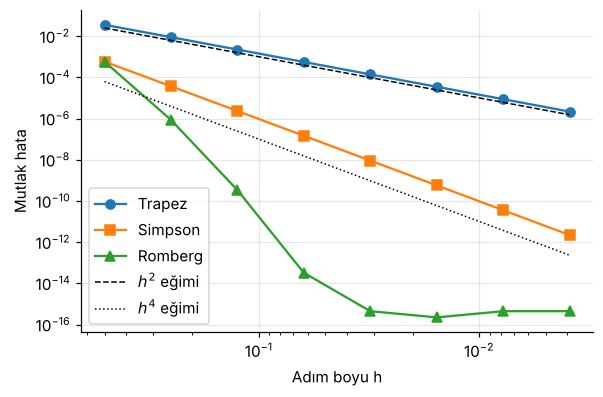

In [6]:
tam = np.e - 1
n_list = 2 ** np.arange(1, 9)
hs = 1 / n_list
hata_T = [abs(trapez(np.exp(np.linspace(0, 1, n + 1)), 1 / n) - tam) for n in n_list]
hata_S = [abs(simpson(np.exp(np.linspace(0, 1, n + 1)), 1 / n) - tam) for n in n_list]
hata_R = [abs(romberg(np.exp(np.linspace(0, 1, n + 1)), 1 / n) - tam) for n in n_list]

plt.figure(figsize=(6, 3.8))
plt.loglog(hs, hata_T, "o-", label="Trapez")
plt.loglog(hs, hata_S, "s-", label="Simpson")
plt.loglog(hs, np.maximum(hata_R, 1e-17), "^-", label="Romberg")
plt.loglog(hs, 0.1 * hs**2, "k--", lw=1, label="$h^2$ eğimi")
plt.loglog(hs, 0.001 * hs**4, "k:", lw=1, label="$h^4$ eğimi")
plt.gca().invert_xaxis()
plt.xlabel("Adım boyu h"); plt.ylabel("Mutlak hata")
plt.legend(); plt.show()

print("Trapez eğimi :", round(np.polyfit(np.log(hs), np.log(hata_T), 1)[0], 2))
print("Simpson eğimi:", round(np.polyfit(np.log(hs[:5]), np.log(hata_S[:5]), 1)[0], 2))

Teoriyle uyumlu: trapez eğimi ≈ 2, Simpson ≈ 4, Romberg birkaç adımda makine hassasiyetine (≈ 10⁻¹⁶) iniyor.
(Simpson'ın son noktaları yuvarlama hatasına takıldığı için eğimi ilk 5 noktadan hesapladık.)

## 4. Gerçek veri: günlük enerji

Her inverter-gün için üç yöntemle integral alıp referansa göre göreli hatayı hesaplıyoruz:
$\text{hata} = |E_{\text{yöntem}} - E_{\text{ref}}|\, /\, E_{\text{ref}}$.

In [7]:
sonuc = pd.DataFrame([
    {"Trapez":  abs(trapez(p, h) - ref[k]) / ref[k],
     "Simpson": abs(simpson(p, h) - ref[k]) / ref[k],
     "Romberg": abs(romberg(p, h) - ref[k]) / ref[k]}
    for k, p in gunler.items()
])
print(f"Ortalama günlük enerji (inverter başına): {np.mean(list(ref.values())):.0f} kWh\n")
tablo = (sonuc.median() * 100).round(2).to_frame("Medyan göreli hata (%)")
tablo

Ortalama günlük enerji (inverter başına): 6982 kWh



,Medyan göreli hata (%)
Trapez,0.28
Simpson,0.43
Romberg,0.50


**Trapez en iyisi**, Simpson ve Romberg daha kötü. Test fonksiyonundaki sıralamanın tam tersi!

## 5. Seyreltme: ölçüm aralığı büyürse ne olur?

Her 2., 4., 8. noktayı alarak 30, 60, 120 dakikalık veri elde ediyoruz ve hatayı tekrar ölçüyoruz.

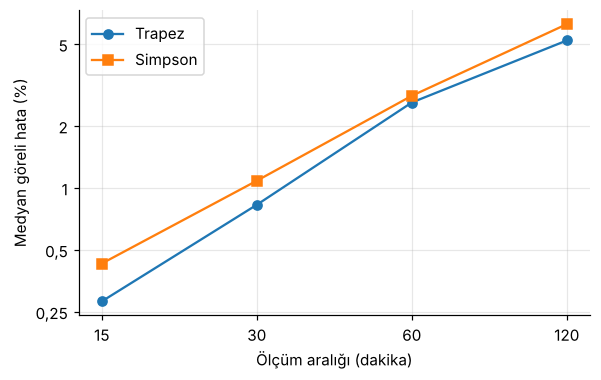

,Trapez (%),Simpson (%)
aralık (dk),,
15,0.28,0.43
30,0.83,1.08
60,2.60,2.80
120,5.21,6.25


In [8]:
seyreltme = [1, 2, 4, 8]                  # 15, 30, 60, 120 dakika
h_dk = [15 * s for s in seyreltme]
med_T, med_S = [], []
for s in seyreltme:
    med_T.append(np.median([abs(trapez(p[::s], h * s) - ref[k]) / ref[k] for k, p in gunler.items()]) * 100)
    med_S.append(np.median([abs(simpson(p[::s], h * s) - ref[k]) / ref[k] for k, p in gunler.items()]) * 100)

plt.figure(figsize=(6, 3.6))
plt.loglog(h_dk, med_T, "o-", label="Trapez")
plt.loglog(h_dk, med_S, "s-", label="Simpson")
plt.xticks(h_dk, h_dk); plt.minorticks_off()
plt.yticks([0.25, 0.5, 1, 2, 5], ["0,25", "0,5", "1", "2", "5"])
plt.xlabel("Ölçüm aralığı (dakika)"); plt.ylabel("Medyan göreli hata (%)")
plt.legend(); plt.show()

pd.DataFrame({"Trapez (%)": med_T, "Simpson (%)": med_S}, index=pd.Index(h_dk, name="aralık (dk)")).round(2)

## Sonuç

* 15 dakikalık veride trapez kuralı günlük enerjiyi **medyan %0,28 hatayla** buluyor. Simpson (%0,43) ve Romberg (%0,50) daha kötü.
* Test fonksiyonunda ($e^x$) ise sıralama teorideki gibi: Romberg > Simpson > trapez. Yöntemlerin mertebeleri doğru çalışıyor; fark verinin kendisinden geliyor.
* **Neden?** Simpson ve Romberg fonksiyonun pürüzsüz olduğunu varsayar. Bu veride bulutlar yüzünden güç eğrisi sık sık zıplıyor, o yüzden yüksek mertebeli yöntemler avantajını kaybediyor. Ayrıca eğrinin iki ucu sıfır, bu da trapezin işine yarıyor.
* Ölçüm aralığı büyüdükçe hata hızla artıyor: 30 dakikada ≈ %0,8, saatlik veride ≈ %2,6, 2 saatlik veride ≈ %5. Seyreltilmiş veride de Simpson trapezi geçemiyor.
* Kalan küçük hatanın kaynağı yöntem değil örnekleme: İki ölçüm arasında geçen bulutları hiçbir kural göremez.